# Ponto 3 — Evolução das regras com *concept drift*

Nos notebooks `1_baseline_sine.ipynb` e `2_rule_evolution.ipynb` usámos o `Sine_synth`, que tem um conceito fixo. Aqui aplicamos a mesma instrumentação (`src/instrumented.py`, sem alterações) a um stream com um drift conhecido. É a experiência mínima da proposta T16.

| | |
|---|---|
| Stream | `ConceptDrift_Agrawal`, 20 000 observações, 9 variáveis, 2 classes |
| Conceito | Função 0 do Agrawal antes do drift e função 2 depois |
| Drift | Gradual, centrado na observação 2 500, com largura 1 000 |
| Janela de drift | Observações 2 000 a 3 000, onde o conceito está a mudar |
| Modelo | UnimNeuron-Safe com os mesmos hiperparâmetros dos notebooks 1 e 2 |
| Execuções | Limite de 5 regras e sem limite |

No baseline, este stream usa a função 0 dos dois lados (só a seed muda), por isso a regra que dá as classes nunca muda e não há drift. Mudámos apenas a função depois do drift. As seeds, a posição, a largura, a ordem das observações e a normalização min-max são as do baseline.

## Desempenho preditivo por fase

In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "ENF_UnimNeuron_Safe.py").is_file())
results = root / "results" / "3_drift_agrawal"
report = json.loads((results / "summary.json").read_text(encoding="utf-8"))
capped, uncapped = report["runs"]["capped"], report["runs"]["uncapped"]

def pct(value):
    return f"{value:.1%}".replace(".", ",")

phases = {"before": "Antes (1 a 1 999)", "drift": "Janela de drift (2 000 a 3 000)",
          "after": "Depois (3 001 a 20 000)", "all": "Stream completo"}
lines = ["| Fase | Accuracy, limite de 5 | Accuracy, sem limite | Balanced accuracy, limite de 5 "
         "| Balanced accuracy, sem limite | Taxa da classe maioritária |",
         "|---|---:|---:|---:|---:|---:|"]
for phase, label in phases.items():
    a, b = capped["predictive"][phase], uncapped["predictive"][phase]
    lines.append(f"| {label} | {pct(a['accuracy'])} | {pct(b['accuracy'])} | "
                 f"{pct(a['balanced_accuracy'])} | {pct(b['balanced_accuracy'])} | "
                 f"{pct(a['majority_rate'])} |")
display(Markdown("\n".join(lines)))

| Fase | Accuracy, limite de 5 | Accuracy, sem limite | Balanced accuracy, limite de 5 | Balanced accuracy, sem limite | Taxa da classe maioritária |
|---|---:|---:|---:|---:|---:|
| Antes (1 a 1 999) | 66,9% | 66,9% | 50,1% | 50,1% | 67,1% |
| Janela de drift (2 000 a 3 000) | 61,4% | 61,4% | 50,0% | 50,0% | 61,4% |
| Depois (3 001 a 20 000) | 52,1% | 52,5% | 49,6% | 49,7% | 53,5% |
| Stream completo | 54,0% | 54,4% | 50,1% | 50,1% | 55,2% |

Para ler a tabela:

- A **taxa da classe maioritária** é a accuracy que se obtém respondendo sempre a classe mais frequente. Um modelo que aprende deve ficar acima dela.
- A **balanced accuracy** é a média do acerto em cada classe. 50% significa que o modelo não distingue as classes.

**O modelo não aprende a separar as classes.** Em todas as fases, a accuracy fica igual ou abaixo da taxa da classe maioritária, e a balanced accuracy fica perto de 50%. Com e sem limite de regras, os resultados são praticamente iguais.

**A accuracy desce de 67% para 52%, mas o modelo não piorou.** Um modelo que responde quase sempre classe 0 acerta tantas vezes quantas as observações que são da classe 0. Antes do drift, 67,1% das observações são da classe 0, por isso a accuracy fica perto de 67%. Depois do drift, só 53,5% são da classe 0, por isso a mesma estratégia passa a acertar só cerca de 53%. O que mudou foi a proporção das classes, não o modelo.

Este comportamento já aparecia na reprodução do baseline (`experiments/results_repro/repro_summary.csv`): sem drift, o Agrawal tinha accuracy de 67,2%, igual à taxa da classe maioritária, e balanced accuracy de 50,0%.

Como a accuracy não mostra o drift, a evidência tem de vir dos eventos das regras, apresentados nas secções seguintes.

## Linha temporal

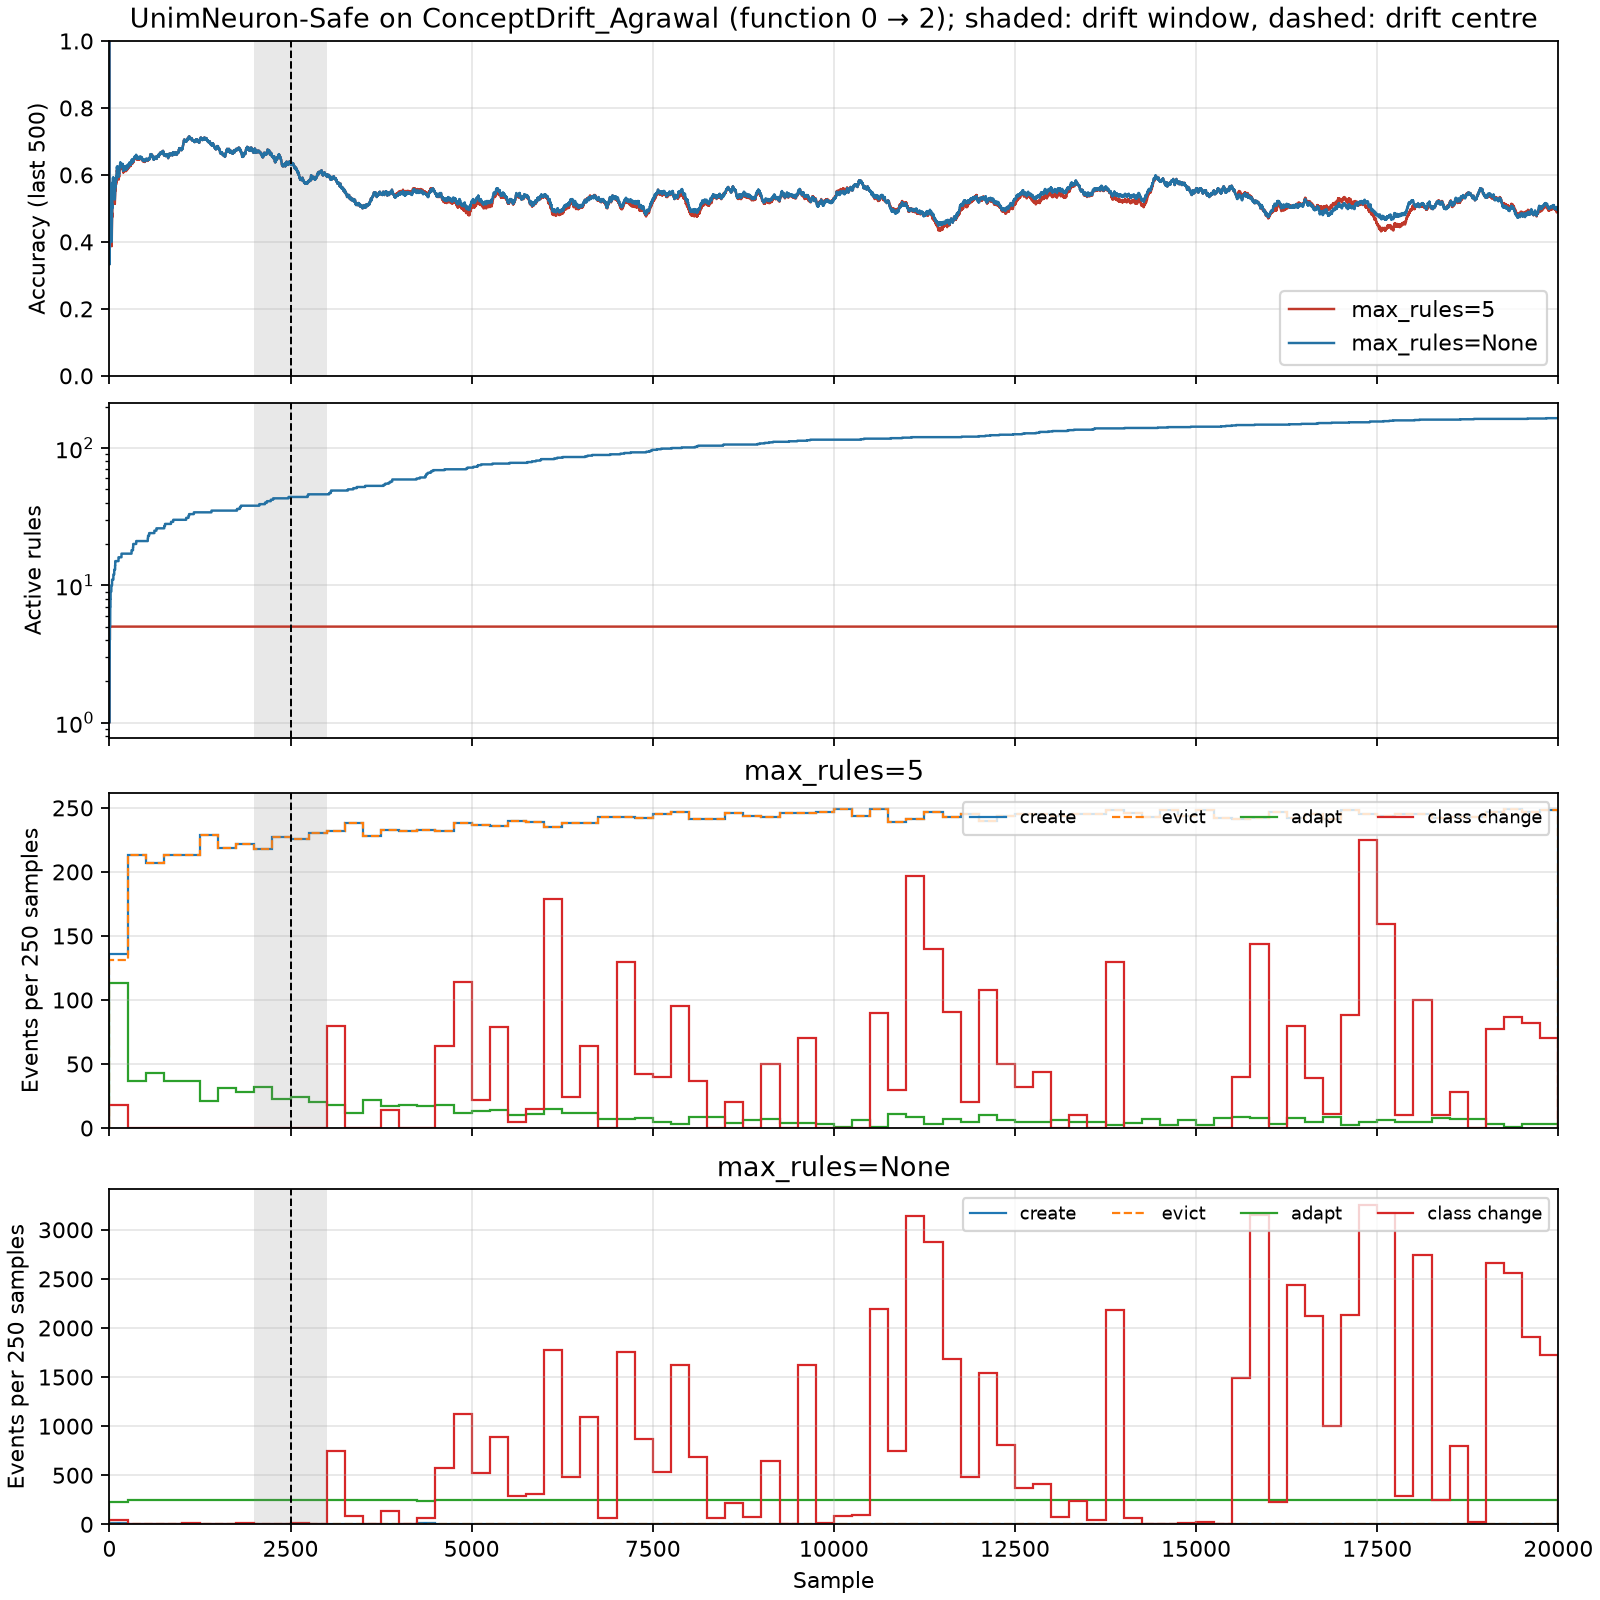

In [2]:
display(Image(filename=str(results / "drift_timeline.png")))

Os quatro gráficos partilham o eixo do tempo (número da observação). A faixa cinzenta é a janela de drift e a linha tracejada o centro do drift.

1. **Accuracy nas últimas 500 observações.** Fica perto de 67% antes do drift, desce durante a janela e oscila à volta de 52% depois. As linhas com e sem limite quase coincidem.
2. **Número de regras ativas** (escala logarítmica). Com limite fica sempre em 5. Sem limite cresce devagar até 165, sem nenhum salto no drift.
3. **Eventos com limite**, por blocos de 250 observações. Criações e remoções estão sobrepostas e quase constantes: em quase todas as observações nasce uma regra e é logo removida. As mudanças de classe estão a zero até ao fim da janela de drift e depois aparecem em picos irregulares.
4. **Eventos sem limite**, por blocos de 250 observações. As adaptações são constantes e as criações são tão poucas que não se veem. As mudanças de classe estão a zero até ao fim da janela de drift e depois disparam, em picos irregulares.

O único sinal do drift são as mudanças de classe, e só aparecem depois da janela de drift.

## Eventos por fase

As duas execuções usam as mesmas 20 000 observações. Para comparar antes e depois do drift, o stream foi dividido em três fases:

| Fase | Observações | Quantas |
|---|---|---|
| Antes | 1 a 1 999 | 1 999 |
| Janela de drift | 2 000 a 3 000 | 1 001 |
| Depois | 3 001 a 20 000 | 17 000 |

Como as fases têm tamanhos diferentes, a tabela não mostra contagens totais, mas o ritmo de cada evento: quantos eventos há, em média, em cada 1 000 observações da fase. Por exemplo, com limite há 18 mudanças de classe nas 1 999 observações antes do drift (9 por 1 000) e 3 336 nas 17 000 observações depois (196 por 1 000). Os valores vêm do `summary.json`, na chave `event_rate_per_1000`.

In [3]:
labels = {"create": "Criações", "evict": "Remoções por limite",
          "adapt": "Adaptações do antecedente", "class_change": "Mudanças de classe"}
lines = ["Eventos por 1 000 observações.", "",
         "| Execução | Evento | Antes | Janela de drift | Depois |", "|---|---|---:|---:|---:|"]
for name, run in (("Limite de 5", capped), ("Sem limite", uncapped)):
    for event, label in labels.items():
        rate = run["event_rate_per_1000"][event]
        lines.append(f"| {name} | {label} | {rate['before']:,.1f} | {rate['drift']:,.1f} | "
                     f"{rate['after']:,.1f} |".replace(",", " ").replace(".", ","))
lines += ["", "| | Limite de 5 | Sem limite |", "|---|---:|---:|",
          f"| Regras criadas | {capped['rules_ever_created']:,} | {uncapped['rules_ever_created']:,} |".replace(",", " "),
          f"| Regras que chegaram a participar numa previsão | {capped['rules_that_ever_predicted']} | {uncapped['rules_that_ever_predicted']} |",
          f"| Candidatas removidas de imediato | {capped['events'].get('immediate_eviction', 0):,} | {uncapped['events'].get('immediate_eviction', 0):,} |".replace(",", " "),
          f"| Regras ativas no fim | {capped['final_rules']} | {uncapped['final_rules']} |"]
display(Markdown("\n".join(lines)))

Eventos por 1 000 observações.

| Execução | Evento | Antes | Janela de drift | Depois |
|---|---|---:|---:|---:|
| Limite de 5 | Criações | 826,4 | 901,1 | 970,0 |
| Limite de 5 | Remoções por limite | 823,9 | 901,1 | 970,0 |
| Limite de 5 | Adaptações do antecedente | 173,6 | 98,9 | 30,0 |
| Limite de 5 | Mudanças de classe | 9,0 | 0,0 | 196,2 |
| Sem limite | Criações | 19,0 | 8,0 | 7,0 |
| Sem limite | Remoções por limite | 0,0 | 0,0 | 0,0 |
| Sem limite | Adaptações do antecedente | 981,0 | 992,0 | 993,0 |
| Sem limite | Mudanças de classe | 39,5 | 18,0 | 3 840,8 |

| | Limite de 5 | Sem limite |
|---|---:|---:|
| Regras criadas | 19 044 | 165 |
| Regras que chegaram a participar numa previsão | 9 | 165 |
| Candidatas removidas de imediato | 19 035 | 0 |
| Regras ativas no fim | 5 | 165 |

## O que os registos mostram

**1. A criação de regras não reage ao drift.** Sem limite, as criações descem de 19,0 para 8,0 e depois 7,0 por 1 000 observações, sem nenhum pico no drift. O modelo decide criar regras sem olhar para a classe (`ENF_UnimNeuron_Safe.py`), e o drift só muda a classe. Por isso, as regras criadas (19 044 com limite e 165 sem limite) são as mesmas que no stream sem drift.

**2. O drift aparece nas mudanças de classe, mas só depois da janela.** Com limite, as mudanças de classe passam de 9,0 antes para 0,0 na janela e 196,2 depois, por 1 000 observações. Sem limite, passam de 39,5 para 18,0 e 3 840,8. Na janela de drift, a classe 0 ainda é maioritária (61,4%), por isso as regras continuam na classe 0. Depois do drift, as classes ficam quase empatadas (53,5%) e as regras começam a mudar de classe.

**3. Depois do drift, as regras oscilam entre classes.** Com limite há só 5 regras ativas, mas 196,2 mudanças de classe por 1 000 observações. Ou seja, cada regra troca de classe muitas vezes, para um lado e para o outro. Sem limite, há 3 840,8 mudanças por 1 000 observações, mais do que uma por observação, porque há várias regras a trocar de classe ao mesmo tempo. O número de regras sem limite vai crescendo ao longo do stream e só chega a 165 no fim. Estas trocas mostram oscilação, não uma adaptação estável ao novo conceito.

**4. Com limite, a estrutura fica congelada.** Criações e remoções acontecem quase ao mesmo ritmo antes, durante e depois do drift (826,4, 901,1 e 970,0 criações por 1 000 observações). Das 19 044 regras criadas, 19 035 foram removidas de imediato e só 9 chegaram a participar numa previsão. Estes eventos não marcam o drift.

## Relação com as hipóteses da proposta

- **H1** é apenas parcialmente confirmada. Sem limite, o drift não cria regras novas, porque a criação não depende da classe. Com e sem limite, o drift aparece nas mudanças de classe, mas só depois da janela de drift e sob a forma de oscilação.
- **H2** é confirmada. Com limite, criações e remoções ocorrem a um ritmo semelhante ao longo de todo o stream e não assinalam o drift.

Este drift só muda a relação entre as variáveis e a classe. Um drift que mude a distribuição das variáveis permitiria testar se os antecedentes das regras reagem. Além disso, como o modelo se aproxima de um preditor da classe maioritária neste stream, a accuracy não serve para medir a recuperação depois do drift.

## Verificação contra o modelo original

Em cada uma das duas execuções, o modelo original e o modelo instrumentado correram lado a lado sobre as mesmas observações. O script compara, em cada observação, a classe prevista e o número de regras depois da atualização, e pára se houver alguma diferença. Também confirma que criações menos remoções dá o número final de regras.

In [4]:
lines = ["| Execução | Observações | Previsões e contagens coincidem | Tempo |", "|---|---:|---|---:|"]
for label, run in (("Limite de 5", capped), ("Sem limite", uncapped)):
    match = "Sim, em todas" if run["exact_match"] else "Não"
    samples = f"{report['samples']:,}".replace(",", " ")
    lines.append(f"| {label} | {samples} | {match} | {run['seconds']:.0f} s |")
display(Markdown("\n".join(lines)))

| Execução | Observações | Previsões e contagens coincidem | Tempo |
|---|---:|---|---:|
| Limite de 5 | 20 000 | Sim, em todas | 11 s |
| Sem limite | 20 000 | Sim, em todas | 164 s |

## Ficheiros e reprodução

Em `results/3_drift_agrawal/`:

| Ficheiro | Conteúdo |
|---|---|
| `*_samples.csv` | Uma linha por observação: previsão, classe real, se acertou, número de regras e regra dominante |
| `*_events.csv.gz` | Os eventos com o estado da regra (sem as atualizações do consequente) |
| `*_lifetimes.csv` | O percurso de cada ID, incluindo o número de mudanças de classe |
| `summary.json` | Desempenho por fase, contagens e taxas de eventos, e verificação |
| `drift_timeline.png` | A linha temporal acima |
| `rule_lifetimes_uncapped.png` | Uma linha por regra sem limite, com a janela de drift marcada |

Para regenerar os ficheiros, seleciona o kernel da `.venv`, muda `repeat_experiment` para `True` e corre a célula seguinte. A execução demora cerca de três minutos, sobretudo por causa do teste sem limite.

In [5]:
import subprocess
import sys

repeat_experiment = False
if repeat_experiment:
    subprocess.run([sys.executable, str(root / "experiments" / "drift_agrawal.py")],
                   cwd=root, check=True)